# Day 6 · pandas + Git + 综合

**上午**：读 pandas 官方『10 minutes to pandas』
**下午**：找一份 CSV 完整分析一遍
**晚上**：用 Git 把本周练习提交到 GitHub

## 1. pandas 基本操作

In [1]:
import pandas as pd
import numpy as np
df = pd.DataFrame({'name': list('abcde'),
                 'city': ['BJ','SH','BJ','SZ','SH'],
                 'score': np.random.randint(60,100,5)})
print(df)
print(df.describe())
print(df[df.score > 80])
print(df.loc[df.city=='BJ', 'score'])
print(df.groupby('city').score.mean())
df.to_csv('demo_df.csv', index=False)

  name city  score
0    a   BJ     67
1    b   SH     65
2    c   BJ     74
3    d   SZ     71
4    e   SH     82
           score
count   5.000000
mean   71.800000
std     6.685806
min    65.000000
25%    67.000000
50%    71.000000
75%    74.000000
max    82.000000
  name city  score
4    e   SH     82
0    67
2    74
Name: score, dtype: int32
city
BJ    70.5
SH    73.5
SZ    71.0
Name: score, dtype: float64


## 2. 缺失值与新增列

In [2]:
df2 = pd.DataFrame({'a':[1,None,3],'b':[None,2,3]})
print(df2.isna().sum())
print(df2.fillna(0))
df2['a_x2'] = df2.a * 2

a    1
b    1
dtype: int64
     a    b
0  1.0  0.0
1  0.0  2.0
2  3.0  3.0


## 3. 下午综合练习
数据二选一：
1. Kaggle Titanic 的 train.csv（第 6 周反正要注册 Kaggle，可以现在注册）
2. 自己造：写 200 行『日期,城市,销量』的 CSV

要做：读取 -> describe -> 缺失值处理 -> 条件筛选 -> groupby 统计 -> 画柱状图，全程写在本 notebook

>>> 1. 正在生成 200 行模拟数据...

>>> 2. 读取 CSV 数据
           日期  城市     销量
0  2023-01-01  广州  674.0
1  2023-01-02  深圳  963.0
2  2023-01-03  北京  842.0
3  2023-01-04  广州  340.0
4  2023-01-05  广州  663.0

>>> 3. 使用 describe() 查看数值统计
               销量
count  180.000000
mean   564.961111
std    250.349038
min    101.000000
25%    332.000000
50%    572.000000
75%    771.250000
max    995.000000

>>> 4. 检查并处理缺失值
各列缺失值数量：
 日期     0
城市     0
销量    20
dtype: int64
填充完毕，填充值为：564.96

>>> 5. 条件筛选：找出销量大于 700 的记录
符合条件的记录有 68 条：
            日期  城市     销量
1   2023-01-02  深圳  963.0
2   2023-01-03  北京  842.0
7   2023-01-08  北京  833.0
11  2023-01-12  广州  848.0
12  2023-01-13  广州  754.0

>>> 6. groupby 统计：计算各城市的总销量和平均销量
             sum        mean
城市                          
广州  31264.727778  578.976440
深圳  30488.844444  564.608230
上海  25734.883333  559.453986
北京  25503.766667  554.429710

>>> 7. 画图展示


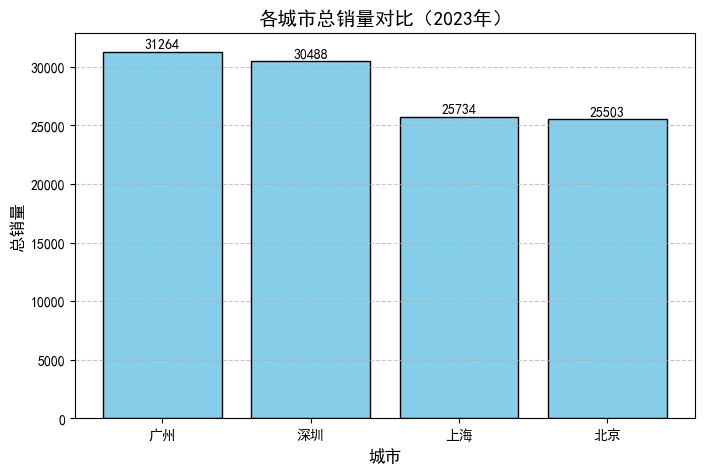

In [3]:
# df = pd.read_csv('...')
# 从这里开始
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==================== 1. 造数据并保存为 CSV ====================
print(">>> 1. 正在生成 200 行模拟数据...")
np.random.seed(42) # 固定随机种子，保证每次生成的数据一样

# 生成日期（200天）、城市（随机4选1）、销量（100~1000的随机数）
dates = pd.date_range('2023-01-01', periods=200, freq='D')
cities = np.random.choice(['北京', '上海', '广州', '深圳'], size=200)
sales = np.random.randint(100, 1000, size=200).astype(float)

# 故意制造 20 个缺失值（NaN）
missing_indices = np.random.choice(200, 20, replace=False)
sales[missing_indices] = np.nan

df_make = pd.DataFrame({'日期': dates, '城市': cities, '销量': sales})
# 存为 CSV（注意加上 encoding='utf-8' 防止中文乱码）
df_make.to_csv('sales_data.csv', index=False, encoding='utf-8')


# ==================== 2. 读取数据 ====================
print("\n>>> 2. 读取 CSV 数据")
df = pd.read_csv('sales_data.csv')
print(df.head()) # 查看前 5 行


# ==================== 3. describe 统计 ====================
print("\n>>> 3. 使用 describe() 查看数值统计")
# describe 默认只看数值列，这里看【销量】的情况
print(df.describe())


# ==================== 4. 缺失值处理 ====================
print("\n>>> 4. 检查并处理缺失值")
print("各列缺失值数量：\n", df.isna().sum())

# 用【销量】列的平均值来填充缺失值（也可以用 0 填充）
mean_sales = df['销量'].mean()
df['销量'] = df['销量'].fillna(mean_sales)
print(f"填充完毕，填充值为：{mean_sales:.2f}")


# ==================== 5. 条件筛选 ====================
print("\n>>> 5. 条件筛选：找出销量大于 700 的记录")
high_sales = df[df['销量'] > 700]
print(f"符合条件的记录有 {len(high_sales)} 条：")
print(high_sales.head())


# ==================== 6. groupby 统计 ====================
print("\n>>> 6. groupby 统计：计算各城市的总销量和平均销量")
# 按城市分组，对销量列计算 sum 和 mean
city_stats = df.groupby('城市')['销量'].agg(['sum', 'mean'])
# 按总销量降序排列，方便后续画图
city_stats = city_stats.sort_values(by='sum', ascending=False)
print(city_stats)


# ==================== 7. 画柱状图 ====================
print("\n>>> 7. 画图展示")
# 设置 matplotlib 支持中文显示（非常重要，否则中文会变成方块）
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows 用黑体
# 如果你是 Mac，把上面这行删掉，换成下面这行：
# plt.rcParams['font.sans-serif'] = ['Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False    # 正常显示负号

plt.figure(figsize=(8, 5))
# 画柱状图：x轴是城市（索引），y轴是总销量
plt.bar(city_stats.index, city_stats['sum'], color='skyblue', edgecolor='black')

plt.title('各城市总销量对比（2023年）', fontsize=14)
plt.xlabel('城市', fontsize=12)
plt.ylabel('总销量', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 在每个柱子上显示具体数值
for i, v in enumerate(city_stats['sum']):
    plt.text(i, v + 100, f'{int(v)}', ha='center', va='bottom', fontsize=10)

plt.show()

## 4. 晚间：Git
1. 安装 Git for Windows（git-scm.com 下载，全部默认下一步；或让 Claude 帮你装）
2. 在 **PowerShell** 里执行下面的命令（换成你的用户名邮箱，并先在 GitHub 建好空仓库 deep-learning-notes）

In [ ]:
# 这些在 PowerShell 里敲，不是在这里：
# cd D:\deep-learning
# git init
# git config --global user.name '你的名字'
# git config --global user.email '你的邮箱'
# git add week1
# git commit -m 'week1 python practice'
# git remote add origin https://github.com/你的用户名/deep-learning-notes.git
# git push -u origin master